# Encontro 12 — Incerteza e sensibilidade

**Modelagem Dinâmica Espacial · LambdaGeo/UFMA**

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lambdageo-edu/curso-modelagem-dinamica-espacial/blob/main/docs/notebooks/encontro12_incerteza_sensibilidade.ipynb)

Sem Python instalado? O selo acima abre este notebook no Google Colab, no navegador. Lá, use *Arquivo → Salvar uma cópia no Drive* antes de mudar qualquer coisa: sem a cópia, o que você escrever se perde ao fechar a página.

Até aqui cada modelo rodou uma vez e produziu um mapa. Mas os coeficientes do potencial são estimativas, a tolerância é uma escolha e a demanda é um cenário. Se um desses valores fosse um pouco diferente, o mapa mudaria muito ou pouco? E quais partes do mapa são confiáveis?

O que vamos fazer:

1. as fontes de incerteza de um modelo de mudança de uso;
2. varrer um coeficiente;
3. medir a sensibilidade a cada coeficiente;
4. rodar muitas vezes, com coeficientes sorteados, e fazer um mapa de concordância;
5. conferir o andamento do projeto.

Usamos o lab15 do encontro 11 (Mojuí dos Campos, alocação discreta), que roda em décimos de segundo.

🔧 = troque um valor e rode de novo; ✏️ = responda.

## 0. Preparação

No Colab, a célula abaixo instala o DisSModel e o DisSLUCC (cerca de 1 minuto). No laboratório o ambiente já está instalado e ela não instala nada.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip install -q "dissmodel==0.6.6" "disslucc==0.5.0"

import contextlib, copy, hashlib, io, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from dissmodel.core import Environment, Model
from dissmodel.geo.raster.backend import RasterBackend
from disslucc import AllocationDClueSLike, DemandPreComputedValues, LogisticRegressionSpec, PotentialDLogisticRegression

GOLDENS = "https://raw.githubusercontent.com/LambdaGeo/luccme-goldens/v1.1.0/sources/labs/data/"
ARQUIVOS = {
    "cs_moju.shp": "19fec700619036cfe9764339c974904647d2ea2f4342f95781b8a182e188c13b",
    "cs_moju.dbf": "e525edd9b1d02d400862bd6f3e8d3af7f6ad3afe89a1b1738c6e4c2eff0857aa",
    "cs_moju.shx": "8bcb68905d6e3d3a75847d1a00ff36d8a034e48691b6ecb62ae2eb859ec2033e",
    "cs_moju.prj": "622ed9a970750e2421b6f6f6e4bc159edf2ae2ba95cb628ba328bf5443c65252",
}

def baixar(nome, sha256, pasta=Path("dados_labs"), tentativas=5):
    destino = pasta / nome
    pasta.mkdir(exist_ok=True)
    for _ in range(tentativas):
        if destino.exists() and hashlib.sha256(destino.read_bytes()).hexdigest() == sha256:
            return destino
        try:
            with urllib.request.urlopen(GOLDENS + nome) as r:
                destino.write_bytes(r.read())
        except Exception:
            time.sleep(2)
    raise RuntimeError(f"{nome}: o arquivo baixado não confere com o hash publicado")

locais = {n: baixar(n, h) for n, h in ARQUIVOS.items()}
moju = gpd.read_file(locais["cs_moju.shp"])
print(len(moju), "células")

5914 células


## 1. De onde vem a incerteza

| Fonte | Exemplo no lab15 | Como se examina |
|---|---|---|
| **Dados** | o mapa de 1999 tem erros de classificação; a distância aos rios depende da escala do mapa de rios | trocar a fonte, comparar resoluções (encontro 10) |
| **Parâmetros** | os coeficientes da logística são estimativas; a tolerância e a elasticidade são escolhas | varrer, medir a sensibilidade, sortear (hoje) |
| **Estrutura** | regressão logística ou outra; alocação discreta ou contínua (encontro 11) | rodar estruturas diferentes e comparar |
| **Cenário** | a demanda futura não é conhecida | cenários (encontro 9): não é incerteza a reduzir, é uma pergunta "e se" |

Hoje mexemos só nos **parâmetros**, e só nos coeficientes do potencial do desmatado. A demanda fica fixa: todas as rodadas desmatam a mesma quantidade, e o que pode mudar é **onde**.

## 2. O modelo base

É o lab15 com tolerância de 10 células, como no encontro 11. A função `novas_celulas` roda o modelo com os coeficientes do desmatado que recebe e devolve quais células foram desmatadas entre 1999 e 2004.

In [2]:
USOS = ["f", "d", "o"]
VARIAVEIS = ["media_decl", "dist_area_", "dist_br", "dist_curua", "dist_rios_", "dist_estra"]
DEMANDA = [[5706, 205, 3], [5658, 253, 3], [5611, 300, 3], [5563, 348, 3], [5516, 395, 3], [5468, 443, 3]]
FLORESTA = LogisticRegressionSpec(const=-2.34187976925989, elasticity=0.0, betas={
    "media_decl": -0.0272710076327129, "dist_area_": 4.30977432375496, "dist_br": 3.10319957497883,
    "dist_curua": 0.445414024051873, "dist_rios_": 47.3556329553235, "dist_estra": 38.4966894254506})
BETAS_D = {"media_decl": 0.0581358851690861, "dist_area_": -0.974998890251365, "dist_br": -2.51650696123426,
           "dist_curua": -1.26742746441679, "dist_rios_": -40.3646901047482, "dist_estra": -23.0841140199094}
OUTROS = LogisticRegressionSpec(const=0.01, elasticity=0.5, betas={})

lin = moju["row"].astype(int).values - moju["row"].astype(int).min()
col = moju["col"].astype(int).values - moju["col"].astype(int).min()
FORMA = (lin.max() + 1, col.max() + 1)
JA_DESMATADA = moju["d"].values == 1


def novas_celulas(betas_d, max_difference=10):
    """Roda o lab15 com estes coeficientes do desmatado; devolve as células desmatadas de 1999 a 2004."""
    grade = RasterBackend(shape=FORMA)
    mascara = np.zeros(FORMA, dtype=np.float32); mascara[lin, col] = 1
    grade.set("mask", mascara)
    for c in USOS + VARIAVEIS:
        a = np.zeros(FORMA, dtype=np.float32); a[lin, col] = moju[c].astype(float).values
        grade.set(c, a)
    desmatado = LogisticRegressionSpec(const=-0.100351497277102, elasticity=0.6, betas=dict(betas_d))
    env = Environment(end_time=len(DEMANDA) - 1)
    dem = DemandPreComputedValues(annual_demand=DEMANDA, land_use_types=USOS)
    PotentialDLogisticRegression(backend=grade, potential_data=[[copy.deepcopy(FLORESTA), desmatado, copy.deepcopy(OUTROS)]],
                                 land_use_types=USOS)
    AllocationDClueSLike(backend=grade, demand=dem, land_use_types=USOS, transition_matrix=[[[1, 1, 0], [0, 1, 0], [0, 0, 1]]],
                         cell_area=1.0, max_difference=max_difference, max_iteration=1000, factor_iteration=0.0001)
    with contextlib.redirect_stdout(io.StringIO()):
        env.run()
    return (np.asarray(grade.get("d"))[lin, col] == 1) & ~JA_DESMATADA


inicio = time.perf_counter()
base = novas_celulas(BETAS_D)
print(f"modelo base: {base.sum()} células novas, em {time.perf_counter() - inicio:.2f} s")

modelo base: 237 células novas, em 0.11 s


## 3. Varrer um coeficiente

No encontro 11, 174 das 237 células novas ficavam a menos de cerca de 500 m de um rio. O coeficiente de `dist_rios_` é o responsável por isso? Multiplicamos esse coeficiente por valores de 0 (sem efeito dos rios) a 2 (o dobro):

In [3]:
COEFICIENTE = "dist_rios_"    # 🔧 experimente "dist_estra" ou "dist_br"
FATORES = [0, 0.5, 1, 1.5, 2]
perto_do_rio = moju["dist_rios_"].values < 0.0045

linhas = []
for fator in FATORES:
    betas = dict(BETAS_D); betas[COEFICIENTE] *= fator
    novas = novas_celulas(betas)
    linhas.append({"fator": fator, "células novas": novas.sum(), "a menos de ~500 m de rio": (novas & perto_do_rio).sum(),
                   "iguais às do modelo base": (novas & base).sum()})
varredura = pd.DataFrame(linhas).set_index("fator")
varredura

,células novas,a menos de ~500 m de rio,iguais às do modelo base
fator,,,
0.0,239,139,202
0.5,242,163,226
1.0,237,174,237
1.5,238,187,224
2.0,237,191,219


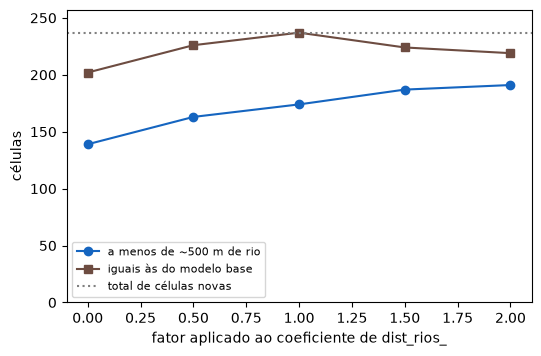

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(varredura.index, varredura["a menos de ~500 m de rio"], "o-", color="#1565c0", label="a menos de ~500 m de rio")
ax.plot(varredura.index, varredura["iguais às do modelo base"], "s-", color="#6d4c41", label="iguais às do modelo base")
ax.axhline(base.sum(), color="grey", ls=":", label="total de células novas")
ax.set(xlabel=f"fator aplicado ao coeficiente de {COEFICIENTE}", ylabel="células", ylim=(0, base.sum() + 20)); ax.legend(fontsize=8);

✏️ **Pergunta 1.** Sem nenhum efeito dos rios (fator 0), quantas células novas ainda ficam perto de um rio? O que isso diz sobre o papel desse coeficiente? (Dica: o desmatamento de 1999 já está perto dos rios, e as estradas também.)

## 4. Sensibilidade a cada coeficiente

Agora mudamos um coeficiente de cada vez, 20% para menos e 20% para mais, e contamos quantas células novas mudam de lugar em relação ao modelo base. É a análise "um de cada vez" (*one-at-a-time*).

,-20%,+20%
media_decl,2,3
dist_area_,1,0
dist_br,8,1
dist_curua,2,3
dist_rios_,4,4
dist_estra,4,1


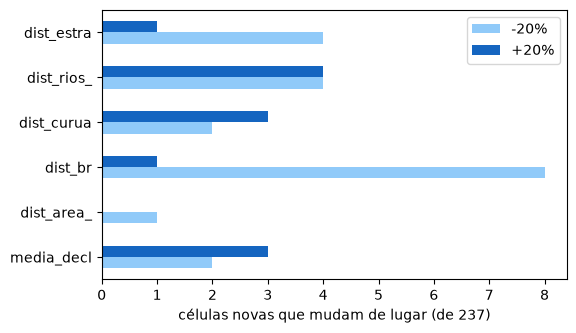

In [5]:
VARIACAO = 0.2    # 🔧 experimente 0.5

sensibilidade = {}
for var in BETAS_D:
    mudadas = []
    for fator in (1 - VARIACAO, 1 + VARIACAO):
        betas = dict(BETAS_D); betas[var] *= fator
        mudadas.append(int((novas_celulas(betas) & ~base).sum()))
    sensibilidade[var] = mudadas
sensibilidade = pd.DataFrame(sensibilidade, index=[f"-{VARIACAO:.0%}", f"+{VARIACAO:.0%}"]).T

fig, ax = plt.subplots(figsize=(6, 3.5))
sensibilidade.plot.barh(ax=ax, color=["#90caf9", "#1565c0"])
ax.set(xlabel=f"células novas que mudam de lugar (de {base.sum()})", ylabel="")
sensibilidade

✏️ **Pergunta 2.** Com 20% de variação, quantas das 237 células mudam de lugar, no pior caso? O mapa do lab15 é sensível ou robusto aos coeficientes? O que mais poderia mexer muito no mapa? (Lembre do encontro 9 e da tolerância.)

## 5. Muitas rodadas, coeficientes sorteados

Os coeficientes não são conhecidos com exatidão. Uma forma de levar isso em conta é rodar o modelo muitas vezes, cada vez com coeficientes sorteados em torno dos originais, e ver em quantas rodadas cada célula foi desmatada. É uma análise de **Monte Carlo**.

Cada rodada usa uma **semente** (encontro 4): a rodada 7 sorteia sempre os mesmos coeficientes, em qualquer computador.

In [6]:
RODADAS = 50      # 🔧
SORTEIO = 0.10    # desvio padrão do fator sorteado (10%); 🔧 experimente 0.3


def coeficientes_sorteados(semente):
    rng = np.random.default_rng(semente)
    return {var: valor * rng.normal(1, SORTEIO) for var, valor in BETAS_D.items()}


inicio = time.perf_counter()
vezes = np.zeros(len(moju))
for semente in range(RODADAS):
    vezes += novas_celulas(coeficientes_sorteados(semente))
concordancia = vezes / RODADAS
print(f"{RODADAS} rodadas em {time.perf_counter() - inicio:.1f} s")

# a mesma semente dá o mesmo mapa
print("rodada 7 repetida igual à primeira vez:",
      np.array_equal(novas_celulas(coeficientes_sorteados(7)), novas_celulas(coeficientes_sorteados(7))))

50 rodadas em 4.0 s
rodada 7 repetida igual à primeira vez: True


nunca                                   5440
desmatada em 90% ou mais das rodadas     216
entre 10% e 90%: incerta                  36
em 10% ou menos: rara                     17


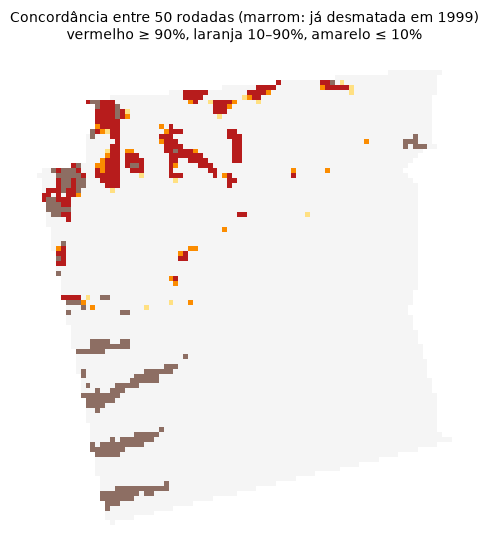

In [7]:
classes = np.select([concordancia >= 0.9, concordancia > 0.1, concordancia > 0], [3, 2, 1], 0)
nomes = {3: "desmatada em 90% ou mais das rodadas", 2: "entre 10% e 90%: incerta",
         1: "em 10% ou menos: rara", 0: "nunca"}
print(pd.Series(classes[~JA_DESMATADA]).map(nomes).value_counts().to_string())

cores = ListedColormap(["#f5f5f5", "#ffe082", "#fb8c00", "#b71c1c"])
fig, ax = plt.subplots(figsize=(6.5, 6.5))
moju.assign(c=np.where(JA_DESMATADA, -1, classes)).plot(
    column="c", cmap=ListedColormap(["#8d6e63"] + list(cores.colors)), vmin=-1, vmax=3, ax=ax)
ax.set_title(f"Concordância entre {RODADAS} rodadas (marrom: já desmatada em 1999)\n"
             "vermelho ≥ 90%, laranja 10–90%, amarelo ≤ 10%", fontsize=10)
ax.set_axis_off()

✏️ **Pergunta 3.** Se você fosse apresentar este resultado a um órgão ambiental, mostraria o mapa do modelo base ou o mapa de concordância? O que cada um comunica, e o que cada um esconde?

✏️ **Pergunta 4.** Este mapa de concordância mede a incerteza **dos coeficientes**. Que incertezas da tabela da Parte 1 ele não inclui?

## 6. Conferência do projeto

Cada aluno mostra, em 3 minutos, o estado do projeto. Use a lista abaixo; o que estiver faltando é o trabalho até o encontro 13 (oficina).

- [ ] **Pergunta**: uma frase, com área e período.
- [ ] **Grade** (encontro 10): o arquivo TOML roda; a figura do `disscube plot` está pronta; o `run.json` guardado.
- [ ] **Demanda**: de onde vem a quantidade de cada ano (tabela observada, taxa, cenário).
- [ ] **Potencial** (encontro 11): a regressão ajustada, com R² e o efeito de um desvio padrão de cada variável.
- [ ] **Alocação**: contínua ou discreta, e por quê; a tolerância escolhida (não a do lab!).
- [ ] **Validação** (encontro 13): qual mapa observado será comparado com o simulado, e de que ano.
- [ ] **Incerteza**: qual parâmetro você vai varrer.

## Para casa

1. Varra a **tolerância** (`max_difference`) do modelo base: 5, 10, 20, 50, 100 e 300. Quantas células novas há em cada caso, e quantas iguais às do modelo base? Compare com a sensibilidade aos coeficientes.
2. Repita a Parte 5 com `SORTEIO = 0.3`. Quantas células passam a ser incertas?
3. Complete a lista da Parte 6 para o seu projeto e traga para o encontro 13.